# Introduction to Pandas library


In this notebook we are going through Pandas library, exploring its functionalities for data wrangling and analysis.

As we have seen, pandas has two basic structures:

 - Series
 - DataFrame

## Pandas Series

A pandas Series is a **one-dimensional labeled array** capable of holding any data type.

Let's explore its basic features and compare it with NumPy arrays.

In [2]:
import pandas as pd
import numpy as np

# Creating a Series from a list
s = pd.Series([1, 3, 5, np.nan, 6, 8])
print("Basic Series:\n", s)
print("\nSeries data type:", type(s))
print("\nSeries index:", s.index)
print("\nSeries values:", s.values)
print("\nSeries data type of values:", type(s.values))

# NumPy array for comparison
np_array = np.array([1, 3, 5, np.nan, 6, 8])
print("NumPy array:\n", np_array)
print("\nNumPy array type:", type(np_array))

Basic Series:
 0    1.0
1    3.0
2    5.0
3    NaN
4    6.0
5    8.0
dtype: float64

Series data type: <class 'pandas.core.series.Series'>

Series index: RangeIndex(start=0, stop=6, step=1)

Series values: [ 1.  3.  5. nan  6.  8.]

Series data type of values: <class 'numpy.ndarray'>
NumPy array:
 [ 1.  3.  5. nan  6.  8.]

NumPy array type: <class 'numpy.ndarray'>


Key differences pandas Series VS numpy array:
- Series has indexed labels, NumPy arrays don't
- Series can have a name
- Series have additional functionalities for data analysis
- Series support inhomogeneous data (types)

In [4]:
# Create a Series with custom index
s_with_index = pd.Series([1, 3, 5, 7, 9], index=['a', 'b', 'c', 'd', 'e'])
print("\nSeries with custom index:")
print(s_with_index)

# Series with name
s_with_index.name = 'my_series'
print("\nSeries with name:")
print(s_with_index)

# Series access by index
print("\nAccessing Series elements:")
print("Value at index 'c':", s_with_index['c'])
print("Values at indexes 'a', 'c', 'e':", s_with_index[['a', 'c', 'e']])

# inhomogeneous data
mixed_s, mixed_np = pd.Series([1, 2, "three"]), np.array([1, 2, "three"])

print("Both Series and array seem to work. However, let's look more closely at results:\n\n",
      f"{mixed_s=}\n\n{mixed_np=}")

print("\n\nCheck first element:", f"{type(mixed_s[0])=}\n{type(mixed_np[0])=}")
print("\nCheck last element:", f"{type(mixed_s[2])=}\n{type(mixed_np[-1])=}")


Series with custom index:
a    1
b    3
c    5
d    7
e    9
dtype: int64

Series with name:
a    1
b    3
c    5
d    7
e    9
Name: my_series, dtype: int64

Accessing Series elements:
Value at index 'c': 5
Values at indexes 'a', 'c', 'e': a    1
c    5
e    9
Name: my_series, dtype: int64
Both Series and array seem to work. However, let's look more closely at results:

 mixed_s=0        1
1        2
2    three
dtype: object

mixed_np=array(['1', '2', 'three'], dtype='<U21')


Check first element: type(mixed_s[0])=<class 'int'>
type(mixed_np[0])=<class 'numpy.str_'>

Check last element: type(mixed_s[2])=<class 'str'>
type(mixed_np[-1])=<class 'numpy.str_'>


### Series operations

In [5]:
# Series operations
print("\nSeries operations:")
print("Series + 5:")
print(s_with_index + 5)
print("\nSeries * 2:")
print(s_with_index * 2)

# Additional Series functionalities
print("\nSeries mean:", s.mean()) # also max(), min(), median()
print("Series standard deviation:", s.std())
print("Series as dictionary:", s.to_dict())


# very similar to dicts, but fast as arrays
print(f"{s.index=}") # instead of dict.keys()
print(f"{s.values=}")


Series operations:
Series + 5:
a     6
b     8
c    10
d    12
e    14
Name: my_series, dtype: int64

Series * 2:
a     2
b     6
c    10
d    14
e    18
Name: my_series, dtype: int64

Series mean: 4.6
Series standard deviation: 2.701851217221259
Series as dictionary: {0: 1.0, 1: 3.0, 2: 5.0, 3: nan, 4: 6.0, 5: 8.0}
s.index=RangeIndex(start=0, stop=6, step=1)
s.values=array([ 1.,  3.,  5., nan,  6.,  8.])


Pandas Series are very similar to numpy arrays. Both are optimized for vectorized operations.
However, Series **can also contain inhomogeneous data (type)**.

**Note:** numpy arrays automatically convert all entries to same type (string).

Moreover, Series enable **labeled retrieval of values**, which can be much better than remembering element position, and more meaningful/readable.

In [6]:
# Creating a Series from a dictionary
cities_population = {'Rome': 2873000, 'Paris': 2161000, 'London': 8982000, 'Berlin': 3645000, 'Madrid': 3223000}
population_series = pd.Series(cities_population)
print("Series from dictionary:")
print(population_series)
print("\nIndex:", population_series.index)
print("\nValues:", population_series.values)

# Filtering Series
print("\nCities with population > 3M:")
print(population_series[population_series > 3000000])

Series from dictionary:
Rome      2873000
Paris     2161000
London    8982000
Berlin    3645000
Madrid    3223000
dtype: int64

Index: Index(['Rome', 'Paris', 'London', 'Berlin', 'Madrid'], dtype='object')

Values: [2873000 2161000 8982000 3645000 3223000]

Cities with population > 3M:
London    8982000
Berlin    3645000
Madrid    3223000
dtype: int64


## Pandas DataFrame

A DataFrame is a 2-dimensional labeled data structure with columns that can be of different types. You can think of it like a spreadsheet or SQL table.

Pandas `DataFrame`s are 2-dimensional labeled data structure with columns that can be of different types.

They are extremely useful and basically reproduce a table format.

On top of that, they also provide powerful features like
- indexing,
- data subsetting,
- data cleaning
- data aggregation
- table merge/join

Let's try to create our first DataFrame!

### Create DataFrame from scratch

#### from Dict

In [9]:
# dataframe from scratch (dict)

data = {
    'City': ['Rome', 'Paris', 'London', 'Berlin', 'Madrid'],
    'Population': [2873000, 2161000, 8982000, 3645000, 3223000],
    'Area': [1285, 105, 1572, 891, 604],
    'Country': ['Italy', 'France', 'UK', 'Germany', 'Spain']
}

df_cities = pd.DataFrame(data)
print("DataFrame from dictionary:")
print(df_cities)

DataFrame from dictionary:
     City  Population  Area  Country
0    Rome     2873000  1285    Italy
1   Paris     2161000   105   France
2  London     8982000  1572       UK
3  Berlin     3645000   891  Germany
4  Madrid     3223000   604    Spain


In [11]:
# Creating a DataFrame with custom index
df_indexed = pd.DataFrame(data, index=data['City'])
print("\nDataFrame with custom index:")
print(df_indexed) # same as df_cities.set_index("City")


DataFrame with custom index:
          City  Population  Area  Country
Rome      Rome     2873000  1285    Italy
Paris    Paris     2161000   105   France
London  London     8982000  1572       UK
Berlin  Berlin     3645000   891  Germany
Madrid  Madrid     3223000   604    Spain


By default, pandas uses an incremental index depending on the size of the dataset.

Alternatively, we can specify a different index at creation, or change it dynamically.

In [12]:
# useful DataFrame methods

print(f"To get dataframe shape: {df_cities.shape=}")
print(f"\nTo get dataframe column names:\n{df_cities.columns=}")
print(f"\nTo get index values:\n{df_cities.index=}")

# to get column values, we have two alternatives
col1 = df_cities['Area']
col2 = df_cities.Population
print(f"\nTo get column values:\n{col1=}\n{col2=}")

To get dataframe shape: df_cities.shape=(5, 4)

To get dataframe column names:
df_cities.columns=Index(['City', 'Population', 'Area', 'Country'], dtype='object')

To get index values:
df_cities.index=RangeIndex(start=0, stop=5, step=1)

To get column values:
col1=0    1285
1     105
2    1572
3     891
4     604
Name: Area, dtype: int64
col2=0    2873000
1    2161000
2    8982000
3    3645000
4    3223000
Name: Population, dtype: int64


#### From List

In [13]:
# Creating a DataFrame from a list of dictionaries
list_of_dicts = [
    {'Name': 'Alice', 'Age': 25, 'City': 'Rome'},
    {'Name': 'Bob', 'Age': 30, 'City': 'Paris'},
    {'Name': 'Charlie', 'Age': 35, 'City': 'London'},
    {'Name': 'Diana', 'Age': 40, 'City': 'Berlin'}
]
df_from_list = pd.DataFrame(list_of_dicts)
print("\nDataFrame from list of dictionaries:")
print(df_from_list)



DataFrame from list of dictionaries:
      Name  Age    City
0    Alice   25    Rome
1      Bob   30   Paris
2  Charlie   35  London
3    Diana   40  Berlin


#### From NumPy

In [14]:
# Creating a DataFrame from a 2D NumPy array
np_array_2d = np.random.randn(5, 4)  # 5 rows, 4 columns of random numbers
df_from_array = pd.DataFrame(np_array_2d,
                           columns=['A', 'B', 'C', 'D'],
                           index=['Row1', 'Row2', 'Row3', 'Row4', 'Row5'])
print("\nDataFrame from 2D NumPy array:")
print(df_from_array)


DataFrame from 2D NumPy array:
             A         B         C         D
Row1  1.178415 -1.207952 -1.321552  2.336945
Row2 -1.391617  0.868480 -0.308811 -0.825699
Row3  1.112994 -1.548108 -0.126563  0.608455
Row4  0.918157 -0.349479  0.571429 -1.699658
Row5 -0.924585  0.273820  0.179200 -0.671164


### Iterating over DataFrames

In case we want to iterate over a DataFrame, we have several options:

- .iterrows()
- .itetuples()
- .items()

While iteration is sometimes necessary, it is **generally slow** compared to vectorized operations.


Below are the main iteration methods:


1️⃣ iterrows() – Row-wise Iteration (Slow, Flexible)

    Iterates over rows, returning index and row as a Series.
    Slower because each row is a separate Pandas Series.
    Useful when working with heterogeneous data (mixed types).

✅ Pros:

✔ **Works with mixed data types**

✔ Easy to read and understand

❌ Cons:

✖ **Slow**, especially on large datasets

✖ Data type **conversion overhead** (each row is a Series)

2️⃣ itertuples() – Row-wise Iteration (Fast, Immutable)

    Iterates over rows, returning each row as a named tuple.
    Much faster than iterrows() because it avoids Pandas’ Series overhead.
    Immutable—modifications require creating a new DataFrame.

✅ Pros:

✔ **Faster than iterrows()**

✔ Access columns as attributes (e.g., row.Name)

❌ Cons:

✖ **Cannot modify DataFrame** during iteration

✖ Still **slower than vectorized operations**

3️⃣ items() – Column-wise Iteration

> previously .iteritems()

    Iterates over columns, returning a tuple of (column_name, column_data as Series).
    Rarely used but helpful when operating on columns separately.

✅ Pros:

✔ Useful for **column-specific** operations

✔ Works well when columns contain independent data

❌ Cons:

✖ Not useful for row-wise operations

✖ **Slower than direct column operations**

In [15]:
iteration_df = pd.DataFrame({
    'Name': ['Alice', 'Bob', 'Charlie'],
    'Age': [25, 30, 35],
    'City': ['Rome', 'Paris', 'London']
})
print("DataFrame for iteration examples:")
print(iteration_df)

DataFrame for iteration examples:
      Name  Age    City
0    Alice   25    Rome
1      Bob   30   Paris
2  Charlie   35  London


In [16]:
# Using iterrows()
print("\nUsing iterrows():")
for index, row in iteration_df.iterrows():
    print(f"Index: {index}, Name: {row['Name']}, Age: {row['Age']}")


Using iterrows():
Index: 0, Name: Alice, Age: 25
Index: 1, Name: Bob, Age: 30
Index: 2, Name: Charlie, Age: 35


In [17]:
# Using itertuples()
print("\nUsing itertuples():")
for row in iteration_df.itertuples():
    print(f"Index: {row.Index}, Name: {row.Name}, Age: {row.Age}")


Using itertuples():
Index: 0, Name: Alice, Age: 25
Index: 1, Name: Bob, Age: 30
Index: 2, Name: Charlie, Age: 35


In [19]:
# Using iteritems() - iterates over columns
print("\nUsing iteritems():")
for column_name, column_values in iteration_df.items():
    print(f"Column: {column_name}, Values: {column_values.values}")


Using iteritems():
Column: Name, Values: ['Alice' 'Bob' 'Charlie']
Column: Age, Values: [25 30 35]
Column: City, Values: ['Rome' 'Paris' 'London']


🚀 **Takeaway**: When Should You Iterate?

    ✅ Use vectorized operations whenever possible — significantly faster!
    ✅ Use .itertuples() instead of .iterrows() for row-wise operations when modification is not needed
    ✅ Use .items() only if processing one column at a time
    ❌ Avoid loops in Pandas unless absolutely necessary
    — Pandas is optimized for bulk operations

💡 **Best Practice:**

Instead of iterating, try to use `.apply()`, `.map()`, `.vectorized` operations, or **groupby()** for efficient computations 🚀

In [20]:
# Example of vectorized operation vs iteration
print("\nVectorized operation example:")
# Slow way (iteration):
# for i, row in df.iterrows():
#     df.loc[i, 'Age_plus_10'] = row['Age'] + 10

# Fast way (vectorized):
iteration_df['Age_plus_10'] = iteration_df['Age'] + 10
print(iteration_df)


Vectorized operation example:
      Name  Age    City  Age_plus_10
0    Alice   25    Rome           35
1      Bob   30   Paris           40
2  Charlie   35  London           45


### Loading data from files

Pandas allows reading data from several types/formats of files.

The most common usage is reading **csv files** (plain text), storing the content into DataFrames.
Of course, many more extensions are supported (e.g. excel, parquet, ...).

Let's try to explore this through the **Boston Housing** dataset.

> **Note: first need to mount gdrive for data access!**

In [3]:
boston_df = pd.read_csv('/content/sample_data/california_housing_train.csv')
print("California Housing Dataset (first 5 rows):")
boston_df.tail()

California Housing Dataset (first 5 rows):


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
16995,-124.26,40.58,52.0,2217.0,394.0,907.0,369.0,2.3571,111400.0
16996,-124.27,40.69,36.0,2349.0,528.0,1194.0,465.0,2.5179,79000.0
16997,-124.30,41.84,17.0,2677.0,531.0,1244.0,456.0,3.0313,103600.0
16998,-124.30,41.80,19.0,2672.0,552.0,1298.0,478.0,1.9797,85800.0
16999,-124.35,40.54,52.0,1820.0,300.0,806.0,270.0,3.0147,94600.0


#### Basic info

In [4]:
# Basic dataset information
print("\nDataset information:")
print(boston_df.info())

# Basic statistics
print("\nBasic statistics:")
print(boston_df.describe())

# Check for missing values
print("\nMissing values count:")
print(boston_df.isnull().sum())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17000 entries, 0 to 16999
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           17000 non-null  float64
 1   latitude            17000 non-null  float64
 2   housing_median_age  17000 non-null  float64
 3   total_rooms         17000 non-null  float64
 4   total_bedrooms      17000 non-null  float64
 5   population          17000 non-null  float64
 6   households          17000 non-null  float64
 7   median_income       17000 non-null  float64
 8   median_house_value  17000 non-null  float64
dtypes: float64(9)
memory usage: 1.2 MB
None

Basic statistics:
          longitude      latitude  housing_median_age   total_rooms  \
count  17000.000000  17000.000000        17000.000000  17000.000000   
mean    -119.562108     35.625225           28.589353   2643.664412   
std        2.005166      2.137340           12.586937 

#### Indexing and data filtering

In [5]:
# Basic column selection
print("Selecting single column:")
print(boston_df['median_house_value'].head())  # Housing price (target variable)

# Selecting multiple columns
selected_cols = ['total_rooms', 'median_income', 'median_house_value']
print("\nSelecting multiple columns:")
print(boston_df[selected_cols].head())

Selecting single column:
0    66900.0
1    80100.0
2    85700.0
3    73400.0
4    65500.0
Name: median_house_value, dtype: float64

Selecting multiple columns:
   total_rooms  median_income  median_house_value
0       5612.0         1.4936             66900.0
1       7650.0         1.8200             80100.0
2        720.0         1.6509             85700.0
3       1501.0         3.1917             73400.0
4       1454.0         1.9250             65500.0


In [6]:
# Row filtering with conditions
print("\nExpensive houses (median_house_value > 30):")
expensive_houses = boston_df[boston_df['median_house_value'] > 30]
print(expensive_houses.head())

# Multiple conditions
print("\nLarge houses (total_rooms > 7) that are expensive (median_house_value > 30):")
large_expensive = boston_df[(boston_df['total_rooms'] > 7) & (boston_df['median_house_value'] > 30)]
print(large_expensive.head())


Expensive houses (median_house_value > 30):
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -114.31     34.19                15.0       5612.0          1283.0   
1    -114.47     34.40                19.0       7650.0          1901.0   
2    -114.56     33.69                17.0        720.0           174.0   
3    -114.57     33.64                14.0       1501.0           337.0   
4    -114.57     33.57                20.0       1454.0           326.0   

   population  households  median_income  median_house_value  
0      1015.0       472.0         1.4936             66900.0  
1      1129.0       463.0         1.8200             80100.0  
2       333.0       117.0         1.6509             85700.0  
3       515.0       226.0         3.1917             73400.0  
4       624.0       262.0         1.9250             65500.0  

Large houses (total_rooms > 7) that are expensive (median_house_value > 30):
   longitude  latitude  housing_median_age  tota

In [7]:
# Using .loc for label-based indexing
print("\nUsing .loc for label-based indexing:")
print(boston_df.loc[0:4, selected_cols])  # rows 0-4, selected columns

# Using .iloc for integer-based indexing
print("\nUsing .iloc for integer-based indexing:")
print(boston_df.iloc[0:5, [0, 5, -1]])  # first 5 rows, columns 0, 5, and last


Using .loc for label-based indexing:
   total_rooms  median_income  median_house_value
0       5612.0         1.4936             66900.0
1       7650.0         1.8200             80100.0
2        720.0         1.6509             85700.0
3       1501.0         3.1917             73400.0
4       1454.0         1.9250             65500.0

Using .iloc for integer-based indexing:
   longitude  population  median_house_value
0    -114.31      1015.0             66900.0
1    -114.47      1129.0             80100.0
2    -114.56       333.0             85700.0
3    -114.57       515.0             73400.0
4    -114.57       624.0             65500.0


In [8]:
# Setting index
boston_indexed = boston_df.set_index('median_house_value')
print("\nDataFrame with median_house_value as index:")
print(boston_indexed.head())

# Reset index
boston_reset = boston_indexed.reset_index()
print("\nDataFrame with reset index:")
print(boston_reset.head())


DataFrame with median_house_value as index:
                    longitude  latitude  housing_median_age  total_rooms  \
median_house_value                                                         
66900.0               -114.31     34.19                15.0       5612.0   
80100.0               -114.47     34.40                19.0       7650.0   
85700.0               -114.56     33.69                17.0        720.0   
73400.0               -114.57     33.64                14.0       1501.0   
65500.0               -114.57     33.57                20.0       1454.0   

                    total_bedrooms  population  households  median_income  
median_house_value                                                         
66900.0                     1283.0      1015.0       472.0         1.4936  
80100.0                     1901.0      1129.0       463.0         1.8200  
85700.0                      174.0       333.0       117.0         1.6509  
73400.0                      337.0       5

In [ ]:
#@title Bonus: Sorting DataFrames

# Sorting
print("\nSorting by median_house_value (descending):")
print(boston_df.sort_values('median_house_value', ascending=False).head())

# Sorting by multiple columns
print("\nSorting by total_rooms (ascending) and MEmedian_house_valueDV (descending):")
print(boston_df.sort_values(['total_rooms', 'median_house_value'], ascending=[True, False]).head())


Sorting by median_house_value (descending):
      longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
8628    -118.53     34.14                28.0       6920.0           906.0   
4398    -118.03     34.16                36.0       1640.0           239.0   
8653    -118.54     34.05                33.0       6778.0          1092.0   
8652    -118.54     34.06                21.0       3755.0           525.0   
4334    -118.01     33.69                 3.0        945.0           115.0   

      population  households  median_income  median_house_value  
8628      2515.0       860.0         9.2189            500001.0  
4398       693.0       253.0         6.6888            500001.0  
8653      2540.0      1052.0         8.5650            500001.0  
8652      1493.0       526.0        11.4233            500001.0  
4334       337.0       123.0        11.5199            500001.0  

Sorting by total_rooms (ascending) and MEmedian_house_valueDV (descending):
       longit

#### SQL-like operations

Pandas allows to perform SQL-like operations using native pandas syntax that covers all typical steps of data management workflows.

Also, pandas offers a limited interface to perform filtering using standard SQL syntax.

> to do that use `df.query('SQL Expression')`

In [43]:
print("SQL-like operations in pandas:")

# SELECT - column selection
print("\nSELECT equivalent (column selection):")
select_result = boston_df[selected_cols]
print(select_result.head())
# Note: .query() cannot be used to select specific columns.
# Use .eval instead: boston_df.eval(selected_cols)

SQL-like operations in pandas:

SELECT equivalent (column selection):
   total_rooms  median_income  median_house_value
0       5612.0         1.4936             66900.0
1       7650.0         1.8200             80100.0
2        720.0         1.6509             85700.0
3       1501.0         3.1917             73400.0
4       1454.0         1.9250             65500.0


In [44]:
# WHERE - filtering
print("\nWHERE equivalent (filtering):")
where_result = boston_df[boston_df['median_house_value'] > 30]
print(where_result.head())
# Using .query() for filtering:
where_result_query = boston_df.query("median_house_value > 30")
print(where_result_query.head())


WHERE equivalent (filtering):
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -114.31     34.19                15.0       5612.0          1283.0   
1    -114.47     34.40                19.0       7650.0          1901.0   
2    -114.56     33.69                17.0        720.0           174.0   
3    -114.57     33.64                14.0       1501.0           337.0   
4    -114.57     33.57                20.0       1454.0           326.0   

   population  households  median_income  median_house_value  
0      1015.0       472.0         1.4936             66900.0  
1      1129.0       463.0         1.8200             80100.0  
2       333.0       117.0         1.6509             85700.0  
3       515.0       226.0         3.1917             73400.0  
4       624.0       262.0         1.9250             65500.0  
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -114.31     34.19                15.0       5612.0          

In [ ]:
# GROUP BY - aggregation
print("\nGROUP BY equivalent (aggregation):")
# Group by total_bedrooms, compute mean for each group
groupby_result = boston_df.groupby('total_bedrooms').mean()
print(groupby_result)
# Note: .query() does not support GROUP BY aggregations.

In [ ]:
# ORDER BY - sorting
print("\nORDER BY equivalent (sorting):")
orderby_result = boston_df.sort_values('median_house_value', ascending=False)
print(orderby_result.head())
# Note: .query() does not support ORDER BY/sorting operations.

In [45]:
# HAVING - filtering on aggregated results
print("\nHAVING equivalent (filtering on aggregated results):")
having_result = boston_df.groupby('households').filter(lambda x: x['median_house_value'].mean() > 25)
# Note: .query() cannot filter on aggregated group results (i.e. perform a HAVING clause).
having_result.head()


HAVING equivalent (filtering on aggregated results):


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
0,-114.31,34.19,15.0,5612.0,1283.0,1015.0,472.0,1.4936,66900.0
1,-114.47,34.40,19.0,7650.0,1901.0,1129.0,463.0,1.8200,80100.0
2,-114.56,33.69,17.0,720.0,174.0,333.0,117.0,1.6509,85700.0
3,-114.57,33.64,14.0,1501.0,337.0,515.0,226.0,3.1917,73400.0
4,-114.57,33.57,20.0,1454.0,326.0,624.0,262.0,1.9250,65500.0


In [ ]:
# COUNT, SUM, AVG - aggregation functions
print("\nCOUNT, SUM, AVG equivalents:")
print("COUNT:", boston_df['total_bedrooms'].value_counts())
print("SUM:", boston_df['median_house_value'].sum())
print("AVG:", boston_df['median_house_value'].mean())
# Note: Aggregation functions (COUNT, SUM, AVG) are not supported via .query().

### Working with dates as index

In [13]:
print("Creating a time series DataFrame:")
date_range = pd.date_range(start='2023-01-01', periods=10, freq='D')
print("Date range:")
print(date_range)

time_series_df = pd.DataFrame({
    'Value': np.random.randn(10),
    'Volume': np.random.randint(100, 1000, size=10)
}, index=date_range)
print("\nTime series DataFrame:")
print(time_series_df)

# Select specific date
print("\nData for specific date (2023-01-05):")
print(time_series_df.loc['2023-01-05'])

# Select date range
print("\nData for date range (2023-01-03 to 2023-01-07):")
print(time_series_df.loc['2023-01-03':'2023-01-07'])

Creating a time series DataFrame:
Date range:
DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03', '2023-01-04',
               '2023-01-05', '2023-01-06', '2023-01-07', '2023-01-08',
               '2023-01-09', '2023-01-10'],
              dtype='datetime64[ns]', freq='D')

Time series DataFrame:
               Value  Volume
2023-01-01  0.490304     370
2023-01-02  0.963621     690
2023-01-03 -0.173771     431
2023-01-04  1.750952     746
2023-01-05  0.595393     329
2023-01-06  0.452239     865
2023-01-07 -0.807016     179
2023-01-08  0.833145     214
2023-01-09  0.195076     378
2023-01-10 -0.597458     235

Data for specific date (2023-01-05):
Value       0.595393
Volume    329.000000
Name: 2023-01-05 00:00:00, dtype: float64

Data for date range (2023-01-03 to 2023-01-07):
               Value  Volume
2023-01-03 -0.173771     431
2023-01-04  1.750952     746
2023-01-05  0.595393     329
2023-01-06  0.452239     865
2023-01-07 -0.807016     179


In [ ]:
#@title Bonus: more advanced fetaures (resampling, lag, rolling windows)

# Resampling - Aggregating to monthly frequency
print("\nResampling to monthly frequency (mean):")
print(time_series_df.resample('M').mean())

# Shifting data (lag)
print("\nShifting data by 2 periods:")
print(time_series_df.shift(periods=2))

# Creating a rolling window
print("\nRolling 3-day window (mean):")
print(time_series_df.rolling(window=3).mean())


Resampling to monthly frequency (mean):
               Value  Volume
2023-01-31 -0.056738   585.3

Shifting data by 2 periods:
               Value  Volume
2023-01-01       NaN     NaN
2023-01-02       NaN     NaN
2023-01-03 -0.232035   543.0
2023-01-04 -2.727392   737.0
2023-01-05 -0.520994   442.0
2023-01-06  0.035036   430.0
2023-01-07  2.369230   862.0
2023-01-08 -0.041309   344.0
2023-01-09  0.855711   213.0
2023-01-10 -0.209356   579.0

Rolling 3-day window (mean):
               Value      Volume
2023-01-01       NaN         NaN
2023-01-02       NaN         NaN
2023-01-03 -1.160141  574.000000
2023-01-04 -1.071117  536.333333
2023-01-05  0.627757  578.000000
2023-01-06  0.787652  545.333333
2023-01-07  1.061210  473.000000
2023-01-08  0.201682  378.666667
2023-01-09  0.410369  552.666667
2023-01-10 -0.101874  760.666667


<ipython-input-78-97a5299975ed>:5: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  print(time_series_df.resample('M').mean())


### Data cleaning

In [14]:
# Create a DataFrame with some issues to clean
print("Creating a dataset with issues to clean:")
np.random.seed(42)
cleaning_df = pd.DataFrame({
    'A': np.random.randn(10),
    'B': [1, 2, np.nan, 4, 5, 6, 7, np.nan, 9, 10],
    'C': ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', np.nan],
    'D': np.random.choice(['X', 'Y', 'Z'], size=10),
    'E': pd.date_range(start='2023-01-01', periods=10)
})
print(cleaning_df)

Creating a dataset with issues to clean:
          A     B    C  D          E
0  0.496714   1.0    a  X 2023-01-01
1 -0.138264   2.0    b  X 2023-01-02
2  0.647689   NaN    c  Y 2023-01-03
3  1.523030   4.0    d  Y 2023-01-04
4 -0.234153   5.0    e  X 2023-01-05
5 -0.234137   6.0    f  X 2023-01-06
6  1.579213   7.0    g  X 2023-01-07
7  0.767435   NaN    h  Z 2023-01-08
8 -0.469474   9.0    i  Z 2023-01-09
9  0.542560  10.0  NaN  Z 2023-01-10


##### Missing values

In [15]:
# Check for missing values
print("\nMissing values count:")
print(cleaning_df.isnull().sum())

# Handling missing values - dropping
print("\nDropping rows with any missing values:")
print(cleaning_df.dropna())


Missing values count:
A    0
B    2
C    1
D    0
E    0
dtype: int64

Dropping rows with any missing values:
          A    B  C  D          E
0  0.496714  1.0  a  X 2023-01-01
1 -0.138264  2.0  b  X 2023-01-02
3  1.523030  4.0  d  Y 2023-01-04
4 -0.234153  5.0  e  X 2023-01-05
5 -0.234137  6.0  f  X 2023-01-06
6  1.579213  7.0  g  X 2023-01-07
8 -0.469474  9.0  i  Z 2023-01-09


In [ ]:
# Handling missing values - filling with fixed value
print("\nFilling numerical missing values with 0:")
print(cleaning_df['B'].fillna(0))

# Filling missing values with method
print("\nFilling missing values with forward fill method:")
print(cleaning_df.fillna(method='ffill'))

# Filling different columns with different strategies
print("\nFilling different columns with different strategies:")
filled_df = cleaning_df.copy()
filled_df['B'] = filled_df['B'].fillna(filled_df['B'].mean())  # Fill B with mean
filled_df['C'] = filled_df['C'].fillna('unknown')  # Fill C with 'unknown'
print(filled_df)


Filling numerical missing values with 0:
0     1.0
1     2.0
2     0.0
3     4.0
4     5.0
5     6.0
6     7.0
7     0.0
8     9.0
9    10.0
Name: B, dtype: float64

Filling missing values with forward fill method:
          A     B  C  D          E
0  0.496714   1.0  a  X 2023-01-01
1 -0.138264   2.0  b  X 2023-01-02
2  0.647689   2.0  c  Y 2023-01-03
3  1.523030   4.0  d  Y 2023-01-04
4 -0.234153   5.0  e  X 2023-01-05
5 -0.234137   6.0  f  X 2023-01-06
6  1.579213   7.0  g  X 2023-01-07
7  0.767435   7.0  h  Z 2023-01-08
8 -0.469474   9.0  i  Z 2023-01-09
9  0.542560  10.0  i  Z 2023-01-10

Filling different columns with different strategies:
          A     B        C  D          E
0  0.496714   1.0        a  X 2023-01-01
1 -0.138264   2.0        b  X 2023-01-02
2  0.647689   5.5        c  Y 2023-01-03
3  1.523030   4.0        d  Y 2023-01-04
4 -0.234153   5.0        e  X 2023-01-05
5 -0.234137   6.0        f  X 2023-01-06
6  1.579213   7.0        g  X 2023-01-07
7  0.767435   5.5

<ipython-input-85-96c554578c1d>:7: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  print(cleaning_df.fillna(method='ffill'))


##### Remove duplicates

In [16]:
# Removing duplicates
duplicated_df = pd.concat([cleaning_df, cleaning_df.iloc[0:3]])
print("\nDataFrame with duplicates:")
print(duplicated_df)

print("\nRemoving duplicates:")
print(duplicated_df.drop_duplicates())


DataFrame with duplicates:
          A     B    C  D          E
0  0.496714   1.0    a  X 2023-01-01
1 -0.138264   2.0    b  X 2023-01-02
2  0.647689   NaN    c  Y 2023-01-03
3  1.523030   4.0    d  Y 2023-01-04
4 -0.234153   5.0    e  X 2023-01-05
5 -0.234137   6.0    f  X 2023-01-06
6  1.579213   7.0    g  X 2023-01-07
7  0.767435   NaN    h  Z 2023-01-08
8 -0.469474   9.0    i  Z 2023-01-09
9  0.542560  10.0  NaN  Z 2023-01-10
0  0.496714   1.0    a  X 2023-01-01
1 -0.138264   2.0    b  X 2023-01-02
2  0.647689   NaN    c  Y 2023-01-03

Removing duplicates:
          A     B    C  D          E
0  0.496714   1.0    a  X 2023-01-01
1 -0.138264   2.0    b  X 2023-01-02
2  0.647689   NaN    c  Y 2023-01-03
3  1.523030   4.0    d  Y 2023-01-04
4 -0.234153   5.0    e  X 2023-01-05
5 -0.234137   6.0    f  X 2023-01-06
6  1.579213   7.0    g  X 2023-01-07
7  0.767435   NaN    h  Z 2023-01-08
8 -0.469474   9.0    i  Z 2023-01-09
9  0.542560  10.0  NaN  Z 2023-01-10


##### Outliers


In [17]:
# Detecting and handling outliers
print("\nDetecting outliers (Z-score method):")
from scipy import stats
z_scores = stats.zscore(boston_df['median_house_value'].dropna())
print("Z-scores:", z_scores)
outliers = np.abs(z_scores) > 2
print("Outliers (Z-score > 2):", boston_df['median_house_value'].loc[outliers])


Detecting outliers (Z-score method):
Z-scores: 0       -1.210558
1       -1.096745
2       -1.048461
3       -1.154514
4       -1.222629
           ...   
16995   -0.826872
16996   -1.106230
16997   -0.894125
16998   -1.047599
16999   -0.971724
Name: median_house_value, Length: 17000, dtype: float64
Outliers (Z-score > 2): 215      500001.0
260      500001.0
809      444100.0
818      477600.0
862      500001.0
           ...   
16421    500001.0
16422    463500.0
16434    500001.0
16482    493800.0
16512    500001.0
Name: median_house_value, Length: 1149, dtype: float64


##### Fix data types

In [18]:
# Data type conversion
print("\nConverting data types:")
print("Original dtype of column D:", cleaning_df['D'].dtype)
cleaning_df['D'] = cleaning_df['D'].astype('category')
print("New dtype of column D:", cleaning_df['D'].dtype)

# String operations
print("\nString operations:")
print("Uppercase conversion:", cleaning_df['C'].str.upper())


Converting data types:
Original dtype of column D: object
New dtype of column D: category

String operations:
Uppercase conversion: 0      A
1      B
2      C
3      D
4      E
5      F
6      G
7      H
8      I
9    NaN
Name: C, dtype: object


#### Aggregation

In [19]:
print("Basic aggregation functions:")
print("\nSum:", boston_df.sum())
print("\nMean:", boston_df.mean())
print("\nMedian:", boston_df.median())
print("\nMin:", boston_df.min())
print("\nMax:", boston_df.max())
print("\nStandard deviation:", boston_df.std())

# Aggregate multiple statistics at once
print("\nMultiple statistics at once:")
print(boston_df.agg(['min', 'max', 'mean', 'median', 'std']))

# Aggregate different functions for different columns
print("\nDifferent aggregations per column:")
print(boston_df.agg({
    'total_rooms': ['min', 'max', 'mean'],
    'median_income': ['mean', 'std'],
    'median_house_value': ['median', 'std', 'count']
}))

# Distribution analysis
print("\nDistribution analysis:")
print("Quantiles:")
print(boston_df.quantile([0.1, 0.25, 0.5, 0.75, 0.9]))

# Histogram
print("\nHistogram bins for median_house_value:")
print(pd.cut(boston_df['median_house_value'], bins=5).value_counts())

# Value counts for categorical data
print("\nValue counts for total_bedrooms (categorical):")
print(boston_df['total_bedrooms'].value_counts())

# Correlation matrix
print("\nCorrelation matrix:")
print(boston_df.corr())

Basic aggregation functions:

Sum: longitude            -2.032556e+06
latitude              6.056288e+05
housing_median_age    4.860190e+05
total_rooms           4.494230e+07
total_bedrooms        9.169984e+06
population            2.430276e+07
households            8.520773e+06
median_income         6.602083e+04
median_house_value    3.524116e+09
dtype: float64

Mean: longitude               -119.562108
latitude                  35.625225
housing_median_age        28.589353
total_rooms             2643.664412
total_bedrooms           539.410824
population              1429.573941
households               501.221941
median_income              3.883578
median_house_value    207300.912353
dtype: float64

Median: longitude               -118.4900
latitude                  34.2500
housing_median_age        29.0000
total_rooms             2127.0000
total_bedrooms           434.0000
population              1167.0000
households               409.0000
median_income              3.5446
median_h

#### Table merge/join

In [22]:
# Create Bologna housing data
print("Creating Bologna housing dataset for merging examples:")
np.random.seed(42)
bologna_housing = pd.DataFrame({
    'property_id': range(1, 11),
    'area_sqm': np.random.uniform(50, 200, size=10).round(0),
    'rooms': np.random.randint(1, 6, size=10),
    'price': np.random.uniform(100000, 500000, size=10).round(-3),
    'neighborhood': np.random.choice(['Centro', 'San Donato', 'Navile', 'Santo Stefano', 'San Vitale'], size=10)
})
print(bologna_housing)

# Create property features dataset
bologna_features = pd.DataFrame({
    'property_id': range(1, 15),  # Note: includes IDs not in housing data
    'has_balcony': np.random.choice([True, False], size=14),
    'floor': np.random.randint(0, 10, size=14),
    'year_built': np.random.randint(1900, 2020, size=14)
})
print("\nBologna property features:")
print(bologna_features)

Creating Bologna housing dataset for merging examples:
   property_id  area_sqm  rooms     price   neighborhood
0            1     106.0      5  273000.0         Centro
1            2     193.0      2  216000.0         Navile
2            3     160.0      4  345000.0     San Vitale
3            4     140.0      2  156000.0         Navile
4            5      73.0      4  217000.0     San Vitale
5            6      73.0      5  247000.0         Centro
6            7      59.0      1  282000.0     San Donato
7            8     180.0      4  414000.0  Santo Stefano
8            9     140.0      2  180000.0         Centro
9           10     156.0      5  306000.0  Santo Stefano

Bologna property features:
    property_id  has_balcony  floor  year_built
0             1        False      7        1989
1             2        False      2        1943
2             3        False      0        1933
3             4         True      3        1973
4             5        False      1        1961
5 

##### Inner join

In [23]:
# Inner join (only matching property_id)
print("\nInner join:")
inner_join = pd.merge(bologna_housing, bologna_features, on='property_id', how='inner')
inner_join


Inner join:


,property_id,area_sqm,rooms,price,neighborhood,has_balcony,floor,year_built
0,1,106.0,5,273000.0,Centro,False,7,1989
1,2,193.0,2,216000.0,Navile,False,2,1943
2,3,160.0,4,345000.0,San Vitale,False,0,1933
3,4,140.0,2,156000.0,Navile,True,3,1973
4,5,73.0,4,217000.0,San Vitale,False,1,1961
5,6,73.0,5,247000.0,Centro,True,7,1999
6,7,59.0,1,282000.0,San Donato,False,3,1913
7,8,180.0,4,414000.0,Santo Stefano,False,1,1994
8,9,140.0,2,180000.0,Centro,False,5,1947
9,10,156.0,5,306000.0,Santo Stefano,True,5,1914


##### Left join

In [24]:
# Left join (all properties from housing data)
print("\nLeft join:")
left_join = pd.merge(bologna_housing, bologna_features, on='property_id', how='left')
left_join


Left join:


,property_id,area_sqm,rooms,price,neighborhood,has_balcony,floor,year_built
0,1,106.0,5,273000.0,Centro,False,7,1989
1,2,193.0,2,216000.0,Navile,False,2,1943
2,3,160.0,4,345000.0,San Vitale,False,0,1933
3,4,140.0,2,156000.0,Navile,True,3,1973
4,5,73.0,4,217000.0,San Vitale,False,1,1961
5,6,73.0,5,247000.0,Centro,True,7,1999
6,7,59.0,1,282000.0,San Donato,False,3,1913
7,8,180.0,4,414000.0,Santo Stefano,False,1,1994
8,9,140.0,2,180000.0,Centro,False,5,1947
9,10,156.0,5,306000.0,Santo Stefano,True,5,1914


##### Right join

In [25]:
# Right join (all properties from features data)
print("\nRight join:")
right_join = pd.merge(bologna_housing, bologna_features, on='property_id', how='right')
right_join


Right join:


,property_id,area_sqm,rooms,price,neighborhood,has_balcony,floor,year_built
0,1,106.0,5.0,273000.0,Centro,False,7,1989
1,2,193.0,2.0,216000.0,Navile,False,2,1943
2,3,160.0,4.0,345000.0,San Vitale,False,0,1933
3,4,140.0,2.0,156000.0,Navile,True,3,1973
4,5,73.0,4.0,217000.0,San Vitale,False,1,1961
5,6,73.0,5.0,247000.0,Centro,True,7,1999
6,7,59.0,1.0,282000.0,San Donato,False,3,1913
7,8,180.0,4.0,414000.0,Santo Stefano,False,1,1994
8,9,140.0,2.0,180000.0,Centro,False,5,1947
9,10,156.0,5.0,306000.0,Santo Stefano,True,5,1914


##### Outer join

In [26]:
# Outer join (all properties from both datasets)
print("\nOuter join:")
outer_join = pd.merge(bologna_housing, bologna_features, on='property_id', how='outer')
outer_join


Outer join:
    property_id  area_sqm  rooms     price   neighborhood  has_balcony  floor  \
0             1     106.0    5.0  273000.0         Centro        False      7   
1             2     193.0    2.0  216000.0         Navile        False      2   
2             3     160.0    4.0  345000.0     San Vitale        False      0   
3             4     140.0    2.0  156000.0         Navile         True      3   
4             5      73.0    4.0  217000.0     San Vitale        False      1   
5             6      73.0    5.0  247000.0         Centro         True      7   
6             7      59.0    1.0  282000.0     San Donato        False      3   
7             8     180.0    4.0  414000.0  Santo Stefano        False      1   
8             9     140.0    2.0  180000.0         Centro        False      5   
9            10     156.0    5.0  306000.0  Santo Stefano         True      5   
10           11       NaN    NaN       NaN            NaN        False      9   
11           12

In [27]:
#@title Bonus: join with different key names

# Create neighborhood data
neighborhood_data = pd.DataFrame({
    'name': ['Centro', 'San Donato', 'Navile', 'Santo Stefano', 'San Vitale'],
    'safety_score': np.random.uniform(7, 10, size=5).round(1),
    'transport_score': np.random.uniform(6, 10, size=5).round(1)
})
print("\nNeighborhood data:")
print(neighborhood_data)

# Join housing with neighborhood data (different key names)
print("\nJoin with different key names:")
neighborhood_join = pd.merge(
    bologna_housing,
    neighborhood_data,
    left_on='neighborhood',  # key in bologna_housing
    right_on='name',         # key in neighborhood_data
    how='left'
)
neighborhood_join


Neighborhood data:
            name  safety_score  transport_score
0         Centro           8.0              7.1
1     San Donato           8.2              8.2
2         Navile           7.8              6.6
3  Santo Stefano           9.5              9.2
4     San Vitale           8.1              6.3

Join with different key names:


,property_id,area_sqm,rooms,price,neighborhood,name,safety_score,transport_score
0,1,106.0,5,273000.0,Centro,Centro,8.0,7.1
1,2,193.0,2,216000.0,Navile,Navile,7.8,6.6
2,3,160.0,4,345000.0,San Vitale,San Vitale,8.1,6.3
3,4,140.0,2,156000.0,Navile,Navile,7.8,6.6
4,5,73.0,4,217000.0,San Vitale,San Vitale,8.1,6.3
5,6,73.0,5,247000.0,Centro,Centro,8.0,7.1
6,7,59.0,1,282000.0,San Donato,San Donato,8.2,8.2
7,8,180.0,4,414000.0,Santo Stefano,Santo Stefano,9.5,9.2
8,9,140.0,2,180000.0,Centro,Centro,8.0,7.1
9,10,156.0,5,306000.0,Santo Stefano,Santo Stefano,9.5,9.2


##### Concatenating DataFrames

In [28]:
# Concatenation (stacking DataFrames)
print("\nConcatenation (vertical stacking):")
bologna_housing_more = pd.DataFrame({
    'property_id': range(11, 16),
    'area_sqm': np.random.uniform(50, 200, size=5).round(0),
    'rooms': np.random.randint(1, 6, size=5),
    'price': np.random.uniform(100000, 500000, size=5).round(-3),
    'neighborhood': np.random.choice(['Centro', 'San Donato', 'Navile', 'Santo Stefano', 'San Vitale'], size=5)
})

concat_result = pd.concat([bologna_housing, bologna_housing_more], axis=0)
# can concat also more than 2 dataframes at a time
# concat_result = pd.concat([bologna_housing, bologna_housing_more, bologna_housing, bologna_housing_more], axis=0)
concat_result


Concatenation (vertical stacking):


,property_id,area_sqm,rooms,price,neighborhood
0,1,106.0,5,273000.0,Centro
1,2,193.0,2,216000.0,Navile
2,3,160.0,4,345000.0,San Vitale
3,4,140.0,2,156000.0,Navile
4,5,73.0,4,217000.0,San Vitale
5,6,73.0,5,247000.0,Centro
6,7,59.0,1,282000.0,San Donato
7,8,180.0,4,414000.0,Santo Stefano
8,9,140.0,2,180000.0,Centro
9,10,156.0,5,306000.0,Santo Stefano


In [ ]:
# Horizontal concatenation
print("\nHorizontal concatenation:")
extra_features = pd.DataFrame({
    'property_id': range(1, 11),
    'has_garage': np.random.choice([True, False], size=10),
    'has_garden': np.random.choice([True, False], size=10)
})

h_concat = pd.concat([bologna_housing, extra_features.set_index('property_id')], axis=1)
h_concat


Horizontal concatenation:


,property_id,area_sqm,rooms,price,neighborhood,has_garage,has_garden
0,1.0,106.0,5.0,273000.0,Centro,NaN,NaN
1,2.0,193.0,2.0,216000.0,Navile,True,False
2,3.0,160.0,4.0,345000.0,San Vitale,False,False
3,4.0,140.0,2.0,156000.0,Navile,False,True
4,5.0,73.0,4.0,217000.0,San Vitale,False,False
5,6.0,73.0,5.0,247000.0,Centro,False,True
6,7.0,59.0,1.0,282000.0,San Donato,False,True
7,8.0,180.0,4.0,414000.0,Santo Stefano,False,False
8,9.0,140.0,2.0,180000.0,Centro,False,True
9,10.0,156.0,5.0,306000.0,Santo Stefano,False,True


In [ ]:
#@title Takeaway message:
from IPython.core.display import HTML
HTML("""
<div class="alert">
  <p>
  - <b>Series vs DataFrames</b>: Series for 1D labeled data, DataFrames for 2D tabular data
  <br>
  - <b>Creation</b>: Multiple ways to create - from dictionaries, lists, arrays, etc.
  <br>
  - <b>Iteration</b>: Prefer vectorized operations, use itertuples() when explicit iteration needed
  <br>
  - <b>Indexing</b>: Use .loc for label-based, .iloc for integer-based indexing
  <br>
  - <b>Filtering</b>: Boolean masks for powerful filtering capabilities
  <br>
  - <b>Cleaning</b>: Handle missing values with fillna(), drop with dropna()
  <br>
  - <b>Aggregation</b>: Descriptive statistics with agg(), groupby(), describe()
  <br>
  - <b>Merging</b>: Combine datasets with merge(), join(), concat()<br>

  <br>
  Remember that pandas is built on NumPy, so many NumPy functions will work directly on pandas objects.
  </p>
</div>

<style>
.alert {
  padding: 20px;
  background-color: #b8e1ff;
  color: #444545;
  margin-bottom: 15px;
}
</style>
""")

## Hands-on Exercise

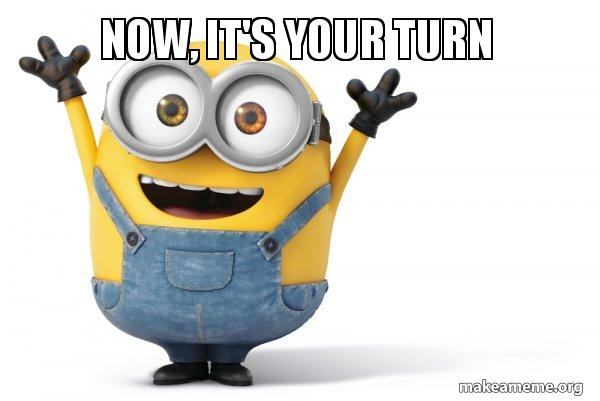

> Exercise: analyze the mock dataset below and complete these tasks (10 minutes):
1. Check for missing values in the dataset. If any, replace them with the mean of the respective column.
2. Create a new column 'BMI_Category' that categorizes BMI into 'Underweight' (<18.5), 'Normal' (18.5-24.9), 'Overweight' (25-29.9), and 'Obese' (>=30)
3. Calculate the mean and standard deviation of glucose levels for each BMI category, grouped by Outcome.
4. Find the correlation between all numeric columns and sort them in descending order relative to 'Outcome'.
5. Create a new DataFrame that only includes women who are over 40 and have had at least 1 pregnancy.
6. Bonus: Create a pivot table that shows the average BMI for each combination of Age group (20-39, 40-59, 60+) and Outcome.

In [ ]:
# mock dataset
print("Pima Indians Diabetes dataset not found, creating mock data...")
np.random.seed(42)
n_samples = 100

pima_df = pd.DataFrame({
    'Pregnancies': np.random.randint(0, 15, size=n_samples),
    'Glucose': np.random.randint(50, 200, size=n_samples),
    'BloodPressure': np.random.randint(40, 120, size=n_samples),
    'SkinThickness': np.random.randint(10, 50, size=n_samples),
    'Insulin': np.random.randint(0, 300, size=n_samples),
    'BMI': np.random.uniform(15, 50, size=n_samples).round(1),
    'DiabetesPedigreeFunction': np.random.uniform(0.1, 1.5, size=n_samples).round(3),
    'Age': np.random.randint(20, 80, size=n_samples),
    'Outcome': np.random.choice([0, 1], size=n_samples, p=[0.65, 0.35])  # 0: No diabetes, 1: Diabetes
})

Pima Indians Diabetes dataset not found, creating mock data...


In [ ]:
#@title Solution

# 1. Check and handle missing values
print("\n1. Checking for missing values:")
print(pima_df.isnull().sum())

# In Pima dataset, 0 values in certain columns are likely missing values
zero_mask = (pima_df['Glucose'] == 0) | (pima_df['BloodPressure'] == 0) | \
            (pima_df['SkinThickness'] == 0) | (pima_df['Insulin'] == 0) | \
            (pima_df['BMI'] == 0)

# Replace 0s with NaN
cols_to_fix = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
pima_df[cols_to_fix] = pima_df[cols_to_fix].replace(0, np.nan)

# Check missing values again
print("Missing values after replacing zeros:")
print(pima_df.isnull().sum())

# Fill missing values with mean
for col in cols_to_fix:
    mean_value = pima_df[col].mean()
    pima_df[col].fillna(mean_value, inplace=True)

print("Missing values after filling with mean:")
print(pima_df.isnull().sum())

# 2. Create BMI category
def bmi_category(bmi):
    if bmi < 18.5:
        return 'Underweight'
    elif bmi < 25:
        return 'Normal'
    elif bmi < 30:
        return 'Overweight'
    else:
        return 'Obese'

pima_df['BMI_Category'] = pima_df['BMI'].apply(bmi_category)
print("\n2. BMI categories:")
print(pima_df['BMI_Category'].value_counts())

# 3. Glucose statistics by BMI category and Outcome
print("\n3. Glucose statistics by BMI category and Outcome:")
glucose_stats = pima_df.groupby(['BMI_Category', 'Outcome'])['Glucose'].agg(['mean', 'std'])
print(glucose_stats)

# 4. Correlations with Outcome
print("\n4. Correlations with Outcome (sorted):")
correlations = pima_df.corr()['Outcome'].sort_values(ascending=False)
print(correlations)

# 5. Women over 40 with at least 1 pregnancy
print("\n5. Women over 40 with at least 1 pregnancy:")
filtered_df = pima_df[(pima_df['Age'] > 40) & (pima_df['Pregnancies'] >= 1)]
print(filtered_df.head())
print(f"Number of women in this group: {len(filtered_df)}")

# 6. Pivot table for BMI by Age group and Outcome
print("\n6. Pivot table for BMI by Age group and Outcome:")
# Create age groups
def age_group(age):
    if age < 40:
        return '20-39'
    elif age < 60:
        return '40-59'
    else:
        return '60+'

pima_df['Age_Group'] = pima_df['Age'].apply(age_group)

# Create pivot table
pivot = pd.pivot_table(
    pima_df,
    values='BMI',
    index='Age_Group',
    columns='Outcome',
    aggfunc='mean'
)
print(pivot)


1. Checking for missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Missing values after replacing zeros:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Missing values after filling with mean:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

2. BMI categories:
BMI_Category
Obese  

<ipython-input-124-f30fcbf1df3e>:23: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  pima_df[col].fillna(mean_value, inplace=True)


ValueError: could not convert string to float: 'Obese'